# Week 4 · Functions, files and modules

**CM3801 · CMT309/509 · CMT124** · shared session · Thursday 29 October 2026

Last week your programs learnt to make decisions and repeat work. Today you package code into **functions** you can reuse and test, use code other people wrote (**modules**), find and fix **bugs**, and make programs that **remember** things by reading and writing **files**.

By the end of today you can define and call your own functions (arguments, defaults, return values, `*args`), explain local and global scope, document a function with a docstring, write a small `lambda`, import `random` and `os`, recognise the three types of errors, and read and write text files with `with open(...)`.

Today has three teaching parts and a lab: **Hour 1** writing functions · **Hour 2** scope, documentation, modules and bugs · **Hour 3** files · **Lab** Guess My Number as functions, and counting words in a file.

### Setup

Hour 3 reads a small text file, `myText.txt`. Run this cell once at the start: `get_data()` returns the file's local path (in Colab it downloads the file the first time).

In [ ]:
# --- Setup: run this cell first -------------------------------------------------
# Course datasets live in the course repository under 2026-27/datasets/.
# get_data() uses a local copy if the notebook runs inside a copy of the repository;
# otherwise (e.g. in Google Colab) it downloads the file once and reuses it.
import os
import urllib.request

COURSE_REPO = "OWNER/REPO"
BASE_URL = f"https://raw.githubusercontent.com/{COURSE_REPO}/main/2026-27/"


def course_file(relpath):
    """Return a local path to a course file such as 'datasets/owid_co2_cleaned.csv'."""
    for root in ("../../..", "."):                     # 1) running inside a copy of the repository
        path = os.path.join(root, relpath)
        if os.path.exists(path):
            return path
    path = os.path.join("course_files", relpath)       # 2) Colab: download once
    if not os.path.exists(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
        urllib.request.urlretrieve(BASE_URL + relpath, path)
    return path


def get_data(name):
    """Return a local path to a course dataset, e.g. get_data('owid_co2_cleaned.csv')."""
    return course_file("datasets/" + name)

my_file = get_data("myText.txt")   # used in Hour 3
print(my_file)

## Hour 1 · Writing functions

### Functions you have used already

You have been calling functions since Week 1. Some are **built-in functions**; others are **methods**, functions attached to an object and called with a dot.

| Built-in functions | Methods |
|---|---|
| `len()`, `range()`, `input()`, `print()`, `int()`, `str()`, `sorted()` | `.upper()`, `.lower()`, `.title()`, `.split()`, `.append()`, `.get()` |

Today you write your **own**.

### A function is a machine

A function bundles up code so you can **reuse** it. It takes **inputs** (arguments), does some work, and sends back an **output** (its return value).

| The general idea | A machine that adds |
|---|---|
| 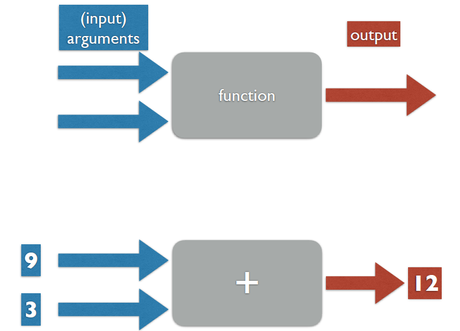 | 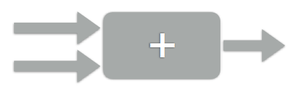 |

```python
def function_name(arguments):
    code block              # indented, like the body of an if or a loop
    return result
```

* `def` creates a **function object** in memory; the name refers to it.
* The arguments in brackets are the **inputs**; `return` sends a value back to the caller.

In [ ]:
# ✍️ Type along: define my_add(x, y), then call it in two ways

<details><summary>Code from class</summary>

```python
def my_add(x, y):
    result = x + y
    return result

print(my_add(5, 6))     # call it with values...

a = 23
b = 47
print(my_add(a, b))     # ...or with variables: the names don't have to match x and y
```

</details>

Defining a function runs **nothing**: it only creates the function. The body runs each time you **call** it, with brackets.

### Calling with arguments

Arguments are matched to parameters **by position**, unless you name them. **Named** (keyword) arguments can come in any order.

**Predict:** what do the two calls print?

In [ ]:
def print_arg(a, b):
    print("First argument:", a, "· second argument:", b)

print_arg(1, 2)
print_arg(b=2, a=1)

Both print the same: in the second call the names, not the positions, decide which value goes where.

### Writing a summing function

**The task:** write `mysum(a, b)` that adds up all the integers from `a` to `b`, **excluding** `b`. For example, `mysum(1, 5)` = 1 + 2 + 3 + 4 = 10. *Hint:* a `for` loop over `range(a, b)` (Week 3).

In [ ]:
# ✍️ Type along: mysum(a, b), the sum of the integers from a to b (excluding b)

<details><summary>Code from class</summary>

```python
def mysum(a, b):
    total = 0
    for i in range(a, b):
        total += i
    return total

mysum(1, 5)     # 10
```

</details>

We call the running total `total`, not `sum`: `sum` is a built-in function, and a variable with that name would hide it.

### Default arguments

A **default argument** is written `name=value`. Python uses the default when the caller doesn't give that argument.

**Predict:** with the default `b=100`, what are `mysum(3, 6)` and `mysum(1)`?

In [ ]:
def mysum(a, b=100):          # sum of the integers from a to b, excluding b
    total = 0
    for i in range(a, b):
        total += i
    return total

print(mysum(3, 6), mysum(1))

`mysum(3, 6)` is 3 + 4 + 5 = **12**. `mysum(1)` uses the default `b=100`: 1 + 2 + … + 99 = **4950**.

**The rules:** arguments **without** defaults come first and must always be given; arguments **with** defaults come at the end and are optional. Python checks this when you define the function:

In [ ]:
# ⚠️ This cell raises an error on purpose
def mysum(a=1, b):
    return a + b

`SyntaxError: parameter without a default follows parameter with a default`. The function is never created.

### Return values and `None`

Every function returns **something**. If there is no `return` statement (or a bare `return`), the function returns `None`.

**Quick check:** `my_print` below prints a message but has no `return`. What is stored in `val`? *(a)* the printed text *(b)* `0` *(c)* `None` *(d)* an error

In [ ]:
def my_print(msg):
    print("-", msg, "-")

val = my_print("Cardiff")
print(val, type(val))

The message is **printed** (shown on the screen), but `val` is **`None`**: nothing was returned. Printing and returning are different things. A caller can only *use* what is returned.

Remember from Week 1: **`None` is falsy: in a Boolean context, it evaluates as `False`.** That does not make it equal to `False` (`None == False` is `False`). To test for it, write `if val is None:`.

`pass` is a placeholder that does nothing. It lets you write the outline of a function now and fill it in later:

In [ ]:
def empty(x, y):
    pass

print(type(empty), type(empty(1, 2)))

### Returning several values

`return` can send back several values at once: Python packs them into a **tuple**, and the caller can **unpack** them (Week 2).

In [ ]:
def min_max(values):
    return min(values), max(values)

low, high = min_max([14.5, 16.0, 12.5, 18.5, 17.0])
print(low, high)

### Any number of arguments: `*args`

Sometimes you don't know how many arguments will be passed. A parameter written with `*` **gathers** all the arguments into one tuple. By convention it is called `args`.

**Predict:** what does `add_all(3, 5, -9, 100)` return? And `add_all()` with no arguments?

In [ ]:
def add_all(*args):
    total = 0
    for x in args:        # args is a tuple, e.g. (3, 5, -9, 100)
        total += x
    return total

print(add_all(3, 5, -9, 100), add_all())

**99** and **0**: with no arguments, `args` is the empty tuple `()`, so the loop never runs. `print()` works the same way: it accepts any number of values.

### Functions change the flow of a program

Like `if` statements and loops, a function call changes the order in which lines run: Python **jumps** into the function body, runs it, and **comes back** to where it was called, bringing the return value with it.

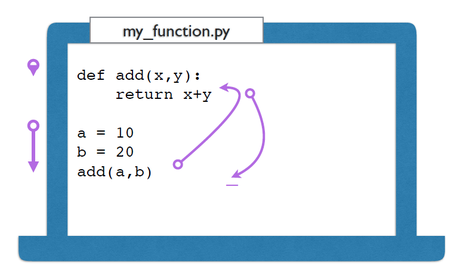

**Your turn:** write a function `c_to_f(celsius)` that converts a temperature from degrees Celsius to Fahrenheit, using °F = °C × 9/5 + 32, and **returns** the result. Check it on values you know: 0 °C is 32 °F, 100 °C is 212 °F, and −40 is the same in both scales.

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
def c_to_f(celsius):
    return celsius * 9 / 5 + 32

print(c_to_f(0), c_to_f(100), c_to_f(-40))   # 32.0 212.0 -40.0
```

Returning (not printing) the result means the caller can keep using it: `c_to_f(18) > 60`, or a list of conversions.

</details>

### Takeaways: writing functions

* `def name(parameters):` creates a function; calling it with brackets runs the body.
* Arguments match by **position** or by **name**; **default** arguments come last and are optional.
* `return` sends a value back. With no `return`, a function returns **`None`**; printing is not returning.
* `return a, b` returns a tuple; `*args` gathers any number of arguments into a tuple.

## Hour 2 · Scope, documentation, modules and bugs

### What happens to the arguments?

Python passes each argument **by object reference**: inside the function, the parameter is a new **name** for the **same object** the caller passed. In the picture, `x` and `a` both refer to `10`.

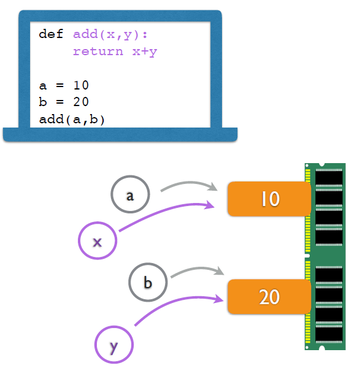

What happens next depends on **mutability** (Week 2).

**Predict:** one function re-binds its parameter; the other changes a list in place. What do the two `print` lines show?

In [ ]:
def add_10(n):
    n = n + 10          # re-binds the local name n only

def add_item(basket, item):
    basket.append(item) # changes the shared list itself

a = 20
shop = ["bread"]
add_10(a)
add_item(shop, "tea")
print(a)
print(shop)

`a` is still **20**: `n = n + 10` made the local name `n` point to a new object, and `a` was never touched. `shop` **has changed** to `['bread', 'tea']`: the function and the caller share the same list, and `.append()` changes that list. Same rule as `y = x` in Week 2.

### Scope: where a name exists

* The main program lives in the **global scope**.
* Each function call creates its own **local scope**. Parameters and the names you assign inside the function live there, and disappear when the function returns.
* A function can **read** global names, but the global scope can't see inside a function, and functions can't see each other's local names.

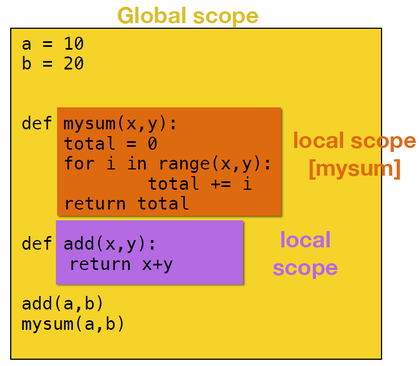

**Before we run this:** `total` is created inside `mysum`. Can the main program see it after the call?

In [ ]:
# ⚠️ This cell raises an error on purpose
def mysum(a, b=100):
    total = 0
    for i in range(a, b):
        total += i
    return total

print(mysum(1, 5))
print(total)

`NameError: name 'total' is not defined`. `total` existed only while `mysum` was running. The caller gets the **value** through `return`, not the variable.

**Before we run this:** both functions try to add 1 to a **global** variable. `fun1` declares `global a` first; `fun2` doesn't. Which one works?

In [ ]:
a, b = 1, 9

def fun1():
    global a          # "a means the global a"
    a += 1

fun1()
print("after fun1, a =", a)

In [ ]:
# ⚠️ This cell raises an error on purpose
def fun2():
    b += 1            # no global statement

fun2()

`fun1` works: `a` is now 2. `fun2` fails with an `UnboundLocalError`: because `fun2` **assigns** to `b`, Python treats `b` as a *local* name, and the local `b` has no value yet.

Use `global` sparingly. A function that takes its inputs as arguments and **returns** its result is much easier to understand and to test.

### Docstrings: documenting a function

A **docstring** is a string in triple quotes placed as the **first statement** of a function. It says what the function does, what it takes and what it returns. `help()` shows it, and it is stored in the special `__doc__` attribute.

In [ ]:
# ✍️ Type along: add a docstring to c_to_f, then read it back with help()

<details><summary>Code from class</summary>

```python
def c_to_f(celsius):
    """Convert a temperature from degrees Celsius to degrees Fahrenheit.

    celsius: a number (int or float).
    Returns the temperature in degrees Fahrenheit (a float).
    """
    return celsius * 9 / 5 + 32

help(c_to_f)
print(c_to_f.__doc__)
```

</details>

Colab shows the docstring when you hover over a function name or type `c_to_f(`. Write one for every function you share with someone else, including your future self.

### Functions are objects too

Everything in Python is an object, functions included. `def` creates a function object and binds a name to it, just as `a = 10` binds `a` to an `int`.

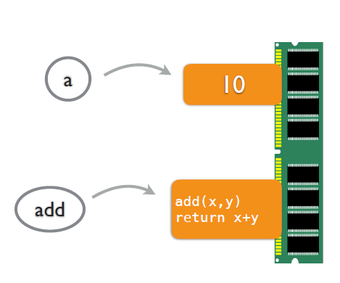

So a function can be given another name, stored in a list, or **passed as an argument** to another function.

In [ ]:
def add(x, y):
    return x + y

plus = add                                  # a second name, no brackets: no call
print(type(add), plus(2, 3))

In [ ]:
def apply(func, x, y):
    return func(x, y)                       # call whatever function was passed in

print(apply(add, 10, 2), apply(max, 10, 2))

`plus` is the **same** function as `add`, so `plus(2, 3)` is 5. `apply` calls the function it receives: `add` gives 12, the built-in `max` gives 10. Without brackets you *refer* to a function; with brackets you *call* it.

### `lambda`: small functions in one line

```python
name = lambda arguments: expression
```

A `lambda` creates a small function object without `def`: any number of arguments, but only **one expression** (no statements, no loops), whose value is returned automatically. It is handy when a function needs another function as an argument, as `sorted` can with `key=`:

In [ ]:
add = lambda x, y: x + y
print(add(10, 2))

cities = [("Cardiff", 362400), ("Newport", 159600), ("Swansea", 238500)]
print(sorted(cities, key=lambda pair: pair[1]))      # sort by the second item

`key=lambda pair: pair[1]` tells `sorted` to compare the populations instead of the names. `lambda` is not the function's name; it only creates the function, and `add = ...` gives it a name.

### Modules: code that someone else wrote

A **module** is a file of ready-made functions (and other objects) that extends Python. `import` loads it, and the **dot** reaches inside it, just like a method. Later in the course you will import `numpy`, `pandas` and `matplotlib` exactly the same way. In Week 3, Guess My Number used `random.randint`.

Run the next cell two or three times and watch the output.

In [ ]:
import random

print(random.randint(1, 10))          # an integer from 1 to 10, both included
print(random.randrange(1000))         # an integer from 0 to 999
print(random.choice(["rock", "paper", "scissors"]))

The values change on every run. Computers produce **pseudo-random** numbers from a starting value, the *seed*. Setting it with `random.seed()` makes the "random" sequence **repeatable**, which is useful when you test a program:

In [ ]:
random.seed(2026)
print([random.randint(1, 6) for i in range(5)])
random.seed(2026)
print([random.randint(1, 6) for i in range(5)])      # the same five rolls again

**Your turn:** write a function `roll_dice(n=2)` that rolls `n` six-sided dice and **returns** their total. Give it a one-line docstring. Call it with the default and with `n=5`.

In [ ]:
import random
# your code here

<details><summary>Answer</summary>

```python
def roll_dice(n=2):
    """Roll n six-sided dice and return the total."""
    total = 0
    for i in range(n):
        total += random.randint(1, 6)
    return total

print(roll_dice(), roll_dice(n=5))
```

With a list comprehension (Week 3) the body fits in one line: `return sum([random.randint(1, 6) for i in range(n)])`.

</details>

### Bugs and debugging

If code does not behave the way it was intended, it contains a **bug**; removing bugs is **debugging**. (In 1947 engineers found a real bug, a moth, stuck in a computer, and taped it into the logbook.) Bugs show up as one of three types of error:

| Type | What happens | Example |
|---|---|---|
| **Syntax** error | the code doesn't run at all: it breaks the rules of the language | `deff` instead of `def`, a missing `:` |
| **Runtime** error | the program starts, then stops with an error message | a name that doesn't exist, dividing by zero |
| **Semantic** error | the program runs and finishes, but the answer is **wrong** | a function called `add` that multiplies |

**Before we run this:** each of the next three cells contains one bug. Which type is each?

In [ ]:
# ⚠️ This cell raises an error on purpose
deff average(values):
    return sum(values) / len(values)

In [ ]:
# ⚠️ This cell raises an error on purpose
def average(values):
    return sum(values) / len(values)

print(average([12.5, 14.0, 15.5]))
print(average([]))                    # an empty list of readings

In [ ]:
def to_fahrenheit(celsius):
    return celsius + 32 * 9 / 5       # looks fine, runs fine...

print(to_fahrenheit(0), to_fahrenheit(100))

1. **Syntax** error: Python refuses to run the cell at all, and points at `deff`.
2. **Runtime** error: the first call works; the second stops with `ZeroDivisionError`. Runtime errors often hide in **special cases** you didn't test, such as an empty list.
3. **Semantic** error: no error message, but 100 °C should be 212 °F, not 157.6. Operator precedence (Week 1) means `32 * 9 / 5` is calculated first. Only a **test against known values** catches it.

**Tools for debugging:** `print()` intermediate values to follow the flow; `type()` to check that a value has the type you expect; and read error messages from the **bottom line up**: the last line says *what* went wrong, the lines above say *where*.

### A very expensive semantic error

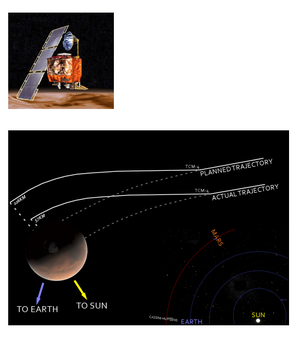

*Images: NASA/JPL-Caltech.*

* In 1999, NASA's robotic space probe, the **Mars Climate Orbiter** (part of a $235.9-million two-spacecraft project), plowed into Mars's upper atmosphere and burnt up.
* Software on the ground (supplied by Lockheed Martin) calculated the thrust of the engines in **pound-seconds**. NASA's navigation software assumed **newton-seconds** (SI units).
* The probe approached Mars far lower than planned, and was lost.

**Discuss:** which type of error lost the probe? Why did no error message warn anyone?

<details><summary>Answer</summary>

A **semantic** error. Every program ran without crashing, and each produced numbers that looked reasonable. The mistake was in the *meaning* of those numbers (their units). Documenting what a function expects (a docstring!) and testing against known values are exactly the habits that catch this.

</details>

### Takeaways: scope, documentation, modules and bugs

* Arguments are passed **by object reference**: changing a list inside a function changes the caller's list; re-binding a name doesn't.
* Names created inside a function are **local**; send results out with `return`, not `global`.
* A **docstring** documents a function: `help(f)` or `f.__doc__`. Functions are objects; `lambda` makes small ones.
* `import module`, then `module.function()`. `random.seed()` makes random results repeatable.
* Errors are **syntax**, **runtime** or **semantic**; only tests catch semantic errors.

## Hour 3 · Files

So far, everything a program creates disappears when it stops. **Files** let a program keep data for later, and read data that someone else produced.

### Text files and binary files

| A text file: human-readable characters | A binary file (an image, an `.exe`): bytes, not text |
|---|---|
| 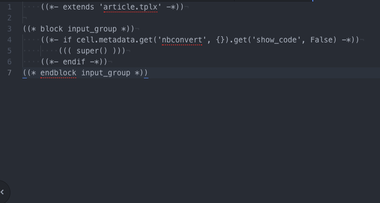 | 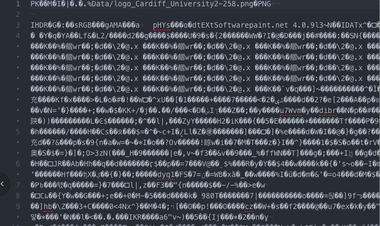 |

Today we work with **text files**: `.txt`, and later `.csv` and `.json`.

### Open and close

`open(filename, mode)` returns a **file object**. The mode says what you want to do: `"r"` to read (the default), `"w"` to write. When you have finished, `close()` the file.

**Predict:** what is `f.closed` before and after `f.close()`?

In [ ]:
f = open(my_file, "r")          # my_file was set in the Setup cell
print(f.name, f.closed)
f.close()
print(f.closed)

`False`, then `True`. A file that is never closed stays open while the program runs; if the program crashes before `close()`, it may never be closed at all. There is a safer way.

### The `with` statement

```python
with open(filename, mode) as f:
    code block          # use f here
# here the file has been closed, even if the code block raised an error
```

### Reading a file

| Method | Returns |
|---|---|
| `f.read()` | the whole file as **one string** |
| `f.read(n)` | the next `n` characters |
| `f.readline()` | the next line, **including** its `\n` |
| `f.readlines()` | a **list** of all the lines |

In [ ]:
# ✍️ Type along: read myText.txt in different ways, using with

<details><summary>Code from class</summary>

```python
with open(my_file, "r") as f:
    text = f.read()
print(text)
print(len(text), "characters")

with open(my_file, "r") as f:
    print(f.read(5))          # 'Hello'
    print(f.readline())       # the rest of the first line
    print(f.readline())       # the second line: reading moves on through the file
```

</details>

Each read **moves on** through the file, like a bookmark. That is why the second `readline()` gives the second line.

**Your turn:** rewrite this cell with a `with` statement, so that you no longer need `f.close()`.

In [ ]:
f = open(my_file, "r")
print(f.readlines())
f.close()

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
with open(my_file, "r") as f:
    print(f.readlines())
```

Notice the `'\n'` at the end of every line except the last: that is the newline character.

</details>

### Looping over a file

A file object is **iterable**: a `for` loop gives you one line at a time, which also works for files far too big to read in one go.

**Predict:** why will the output below have an empty line between every two lines of text?

In [ ]:
with open(my_file, "r") as f:
    for line in f:
        print(line)

Each `line` already ends with `\n`, and `print()` adds another one. `print(line.rstrip("\n"))`, or `print(line, end="")`, prints each line once. `.strip()` also removes spaces and tabs at the ends.

**Your turn:** count the lines in `myText.txt` with a `for` loop over the file. Then count the **words** too. *Hint:* `.split()` (Week 1) splits a line into a list of words.

In [ ]:
# your code here

<details><summary>Answer</summary>

```python
n_lines = 0
n_words = 0
with open(my_file, "r") as f:
    for line in f:
        n_lines += 1
        n_words += len(line.split())
print(n_lines, "lines,", n_words, "words")     # 6 lines, 36 words
```

`len(f.readlines())` also counts the lines, but it reads the whole file into memory first.

</details>

### Writing a file: access modes

| Mode | Meaning |
|---|---|
| `"r"` | read; error if the file doesn't exist (the default) |
| `"w"` | write; **creates** the file, or **empties** it if it already exists |
| `"a"` | append; adds to the end of the file (creates it if needed) |
| `"r+"`, `"w+"`, `"a+"` | read and write; same rules for creating and emptying as above |

`f.write(text)` writes one string; `f.writelines(list_of_strings)` writes several. Neither adds `\n` for you.

We write to a **new** file, `week4_notes.txt`, in the notebook's working folder. (Never open your input data with `"w"`!)

**Predict:** the next cell writes to `week4_notes.txt` twice, both times with mode `"w"`. What does the file contain at the end?

In [ ]:
with open("week4_notes.txt", "w") as f:
    f.write("Functions\n")
    f.writelines(["Scope\n", "Modules\n"])

with open("week4_notes.txt", "w") as f:      # the same file, "w" again
    f.write("Files\n")

In [ ]:
with open("week4_notes.txt", "r") as f:
    print(f.read())

Only `Files`. Opening an existing file with `"w"` **empties it first**, without a warning. To add to the end instead, use `"a"`:

In [ ]:
with open("week4_notes.txt", "a") as f:
    f.write("Debugging\n")

with open("week4_notes.txt", "r") as f:
    print(f.readlines())

### Functions and files together

Now combine the two halves of today: a function produces values, and a file keeps them.

In [ ]:
# ✍️ Type along: write a conversion table, one "celsius,fahrenheit" line per row, to temperatures.txt

<details><summary>Code from class</summary>

```python
def c_to_f(celsius):
    return celsius * 9 / 5 + 32

with open("temperatures.txt", "w") as f:
    f.write("celsius,fahrenheit\n")
    for c in range(-10, 41, 10):
        f.write(f"{c},{c_to_f(c)}\n")

with open("temperatures.txt", "r") as f:
    print(f.read())
```

</details>

A file of comma-separated values like this is a **CSV** file. In Week 6, pandas reads files like this in one line.

### Where are my files? The `os` module

Relative names such as `"week4_notes.txt"` are looked up in the **current working directory**. The `os` module lets Python look at folders and files.

In [ ]:
import os

print(os.getcwd())                          # the current working directory
print(os.path.exists("week4_notes.txt"), os.path.exists("no_such_file.txt"))
print(os.path.isfile(my_file), os.path.isdir(os.getcwd()))
print(os.path.join("data", "myText.txt"))   # builds a path with the right separator

`os.listdir()` lists the contents of a folder, and `os.chdir(path)` changes the working directory (and with it the meaning of every relative file name, so use it with care). In Colab the working directory is `/content`: the files you wrote appear in the **Files** panel on the left, and they disappear when the runtime is reset.

**Quick check:** you want to add today's readings to the end of an existing `log.txt` without losing what's there. Which mode? *(a)* `"r"` *(b)* `"w"` *(c)* `"a"`

<details><summary>Answer</summary>

*(c)* `"a"`. `"w"` would empty the log first; `"r"` can't write at all.

</details>

### Takeaways: files

* `with open(path, mode) as f:` opens a file and **always** closes it.
* Read with `read()`, `readline()`, `readlines()`, or loop over `f` line by line; each line ends with `\n`.
* `"w"` creates **or empties** a file; `"a"` appends; `write()` doesn't add newlines.
* `os.getcwd()` and `os.path.exists()` tell you where you are and what is there.

## Transition to the lab

**You now know** how to package code as functions with arguments, defaults and return values, how to test a function with known values, and how to read and write text files.

**The lab** (`W04_lab_student.ipynb`, one hour) practises exactly this:
* **Part A** turns your Week 3 Guess My Number game into small functions, `give_hint()`, `get_guess()` and `play()`, and tests each one with `assert`.
* **Part B** writes `word_count(path)` for `myText.txt` and saves the results to a new file.

## Week 4 takeaways

* A **function** takes arguments, runs its body when called, and **returns** a value (or `None`).
* **Default** arguments make functions flexible; **docstrings** make them usable by others.
* Names inside a function are **local**; mutable arguments can be changed in place.
* `import` gives you modules such as `random` and `os`; the dot reaches inside them.
* **Syntax**, **runtime** and **semantic** errors need different hunting; test against known answers.
* Files: `with open(...)`, read or loop line by line, and write with `"w"` (careful!) or `"a"`.

## Where next

**Week 5 · Numerical data with NumPy.** You will `import numpy as np`, a module built for numbers, and replace many of today's loops (like `mysum` and `add_all`) with single operations on whole **arrays** of data.

Before next week: reopen this notebook, run it top to bottom, and finish any *Your turn* you skipped.

## Optional: explore after class

These extras are not needed for Week 5.

**Position in a file.** A file object keeps an internal position (an index), like an index into one long string. It starts at 0 and moves as you read or write. `f.tell()` returns the position; `f.seek(n)` moves it back to position `n`.

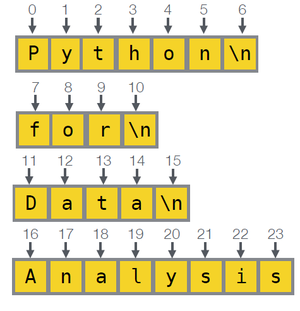

In [ ]:
with open(my_file, "r") as f:
    print(f.read(5), f.tell())     # 'Hello', and the position is now 5
    f.seek(0)                      # back to the start
    print(f.readline())

**Binary files.** Adding `b` to the mode (`"rb"`, `"wb"`) opens a file in **binary** mode: reads return a `bytes` object instead of a string.

In [ ]:
with open(my_file, "rb") as f:
    data = f.read(12)
print(data, type(data))

## Credits

Images: Mars Climate Orbiter and its trajectory, NASA/JPL-Caltech. The text file `myText.txt` is a course teaching file.